In [69]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from  sklearn.tree import DecisionTreeClassifier

In [70]:
df = pd.read_csv("DGA.csv")
df.head()

,NM,H2,CH4,C2H6,C2H4,C2H2,Type
0,1,3930.0,2397.0,157.0,0.0,0.0,Partial discharge
1,2,37800.0,1740.0,249.0,8.0,8.0,Partial discharge
2,3,92600.0,10200.0,0.0,0.0,0.0,Partial discharge
3,4,8266.0,1061.0,22.0,0.0,0.0,Partial discharge
4,5,9340.0,995.0,60.0,6.0,7.0,Partial discharge


In [71]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [72]:
label = LabelEncoder()
df["Type"] = label.fit_transform(df["Type"])

In [73]:
df.head()

,NM,H2,CH4,C2H6,C2H4,C2H2,Type
0,1,3930.0,2397.0,157.0,0.0,0.0,5
1,2,37800.0,1740.0,249.0,8.0,8.0,5
2,3,92600.0,10200.0,0.0,0.0,0.0,5
3,4,8266.0,1061.0,22.0,0.0,0.0,5
4,5,9340.0,995.0,60.0,6.0,7.0,5


In [74]:
df.isnull().sum()

NM      0
H2      0
CH4     0
C2H6    0
C2H4    0
C2H2    0
Type    0
dtype: int64

In [75]:
print(df["Type"].value_counts())

Type
0    54
6    49
1    38
2    19
5    16
3    16
4     9
Name: count, dtype: int64


In [76]:
print(label.classes_)

['Arc discharge' 'High-temperature overheating'
 'Low-temperature overheating' 'Low/Middle-temperature overheating'
 'Middle-temperature overheating' 'Partial discharge' 'Spark discharge']


In [77]:
print(df.describe())

               NM            H2           CH4          C2H6          C2H4  \
count  201.000000    201.000000    201.000000    201.000000    201.000000   
mean   101.000000   3409.096264   2072.968607    870.094483   2119.031791   
std     58.167861   9361.233289   7003.430100   5805.765812   8379.752492   
min      1.000000      0.000000      0.000000      0.000000      0.000000   
25%     51.000000     65.000000     40.000000      7.000000     11.200000   
50%    101.000000    388.000000    180.830000     30.000000    166.000000   
75%    151.000000   2240.000000   1069.000000    175.000000    900.000000   
max    201.000000  92600.000000  64064.000000  72128.000000  95650.000000   

               C2H2        Type  
count    201.000000  201.000000  
mean    1227.884527    2.656716  
std     5096.020447    2.395113  
min        0.000000    0.000000  
25%        1.000000    0.000000  
50%       31.100000    2.000000  
75%      634.000000    5.000000  
max    57000.000000    6.000000  


In [78]:
x = df.drop(["NM", "Type"], axis = 1)
y = df["Type"]

In [79]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42, stratify = y)

In [80]:
x_train.shape, y_train.shape

((160, 5), (160,))

In [81]:
df_gini = DecisionTreeClassifier(criterion = "gini", max_depth = 2, random_state = 0) 
df_gini.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [82]:
y_pred_gini = df_gini.predict(x_test)

In [83]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [84]:
accuracy = accuracy_score(y_test, y_pred_gini)
accuracy

0.4634146341463415

In [85]:
cm = confusion_matrix(y_test, y_pred_gini)
print(cm)

[[10  0  0  0  0  0  1]
 [ 5  3  0  0  0  0  0]
 [ 0  0  4  0  0  0  0]
 [ 2  0  1  0  0  0  0]
 [ 0  2  0  0  0  0  0]
 [ 0  0  3  0  0  0  0]
 [ 5  0  3  0  0  0  2]]


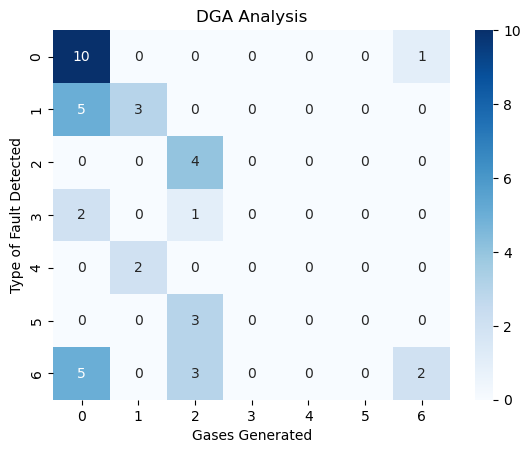

In [86]:
sns.heatmap(cm, annot = True, fmt="d", cmap = "Blues")
plt.xlabel("Gases Generated")
plt.ylabel("Type of Fault Detected")
plt.title("DGA Analysis")
plt.show()

In [87]:
from sklearn import tree 

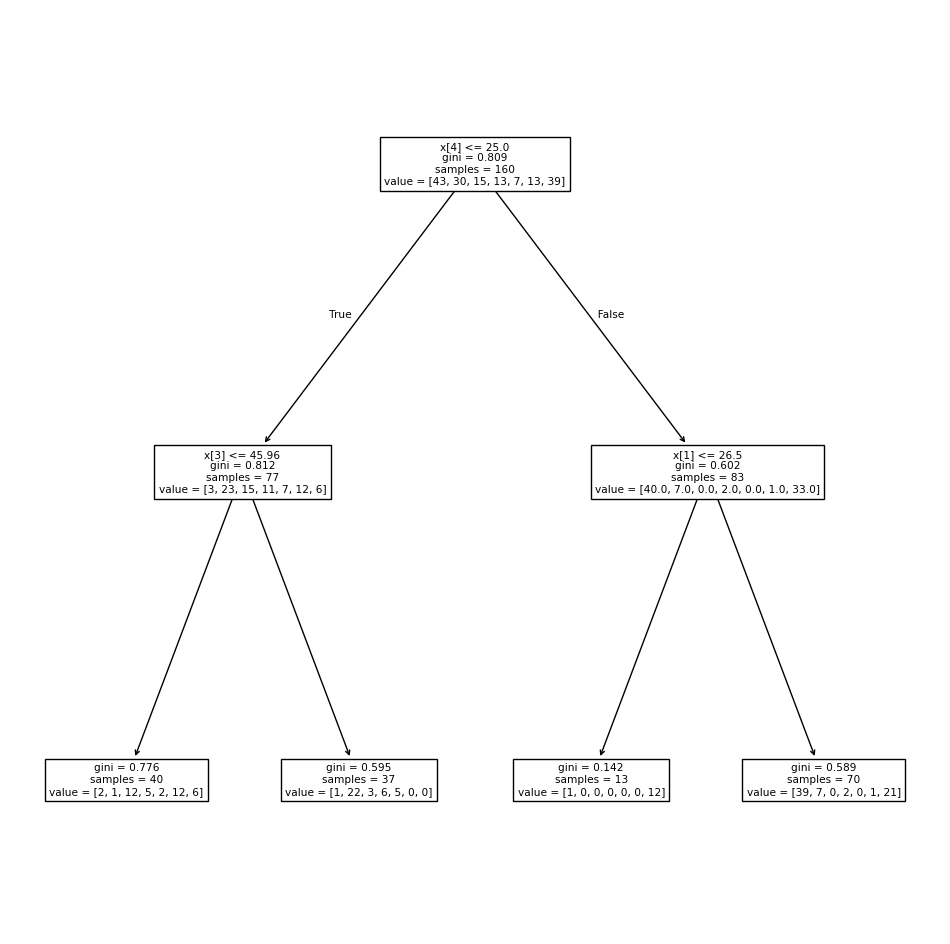

In [88]:
plt.figure(figsize = (12,12))
tree.plot_tree(df_gini)
plt.show()

In [89]:
from sklearn.tree import plot_tree

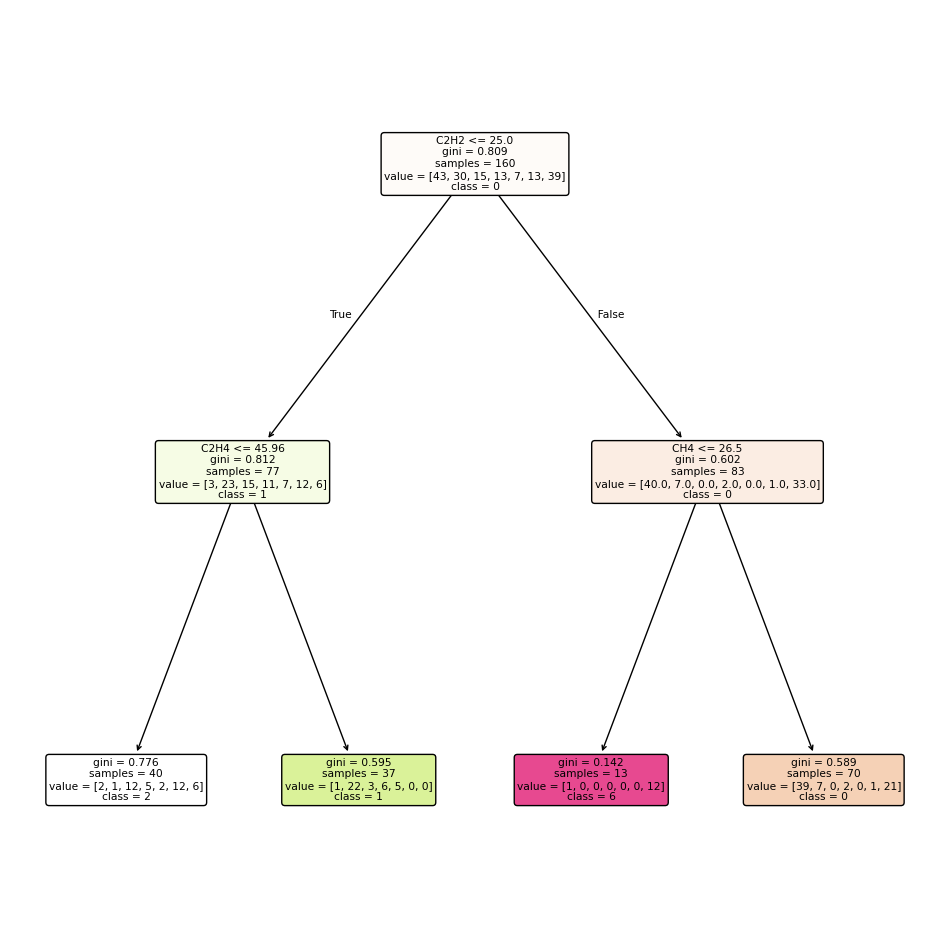

In [90]:
plt.figure(figsize = (12,12))
plot_tree(df_gini, feature_names = x.columns, class_names = [str(c) for c in df_gini.classes_], filled = True, rounded = True)
plt.show()

In [91]:
print(classification_report(y_test, y_pred_gini))

              precision    recall  f1-score   support

           0       0.45      0.91      0.61        11
           1       0.60      0.38      0.46         8
           2       0.36      1.00      0.53         4
           3       0.00      0.00      0.00         3
           4       0.00      0.00      0.00         2
           5       0.00      0.00      0.00         3
           6       0.67      0.20      0.31        10

    accuracy                           0.46        41
   macro avg       0.30      0.35      0.27        41
weighted avg       0.44      0.46      0.38        41



C:\Users\gupta\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\gupta\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\gupta\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [92]:
df_en = DecisionTreeClassifier(criterion = "entropy", max_depth = 2, random_state = 0) 
df_en.fit(x_train, y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [93]:
y_pred_en = df_en.predict(x_test)

In [94]:
accuracy = accuracy_score(y_test, y_pred_en)
accuracy

0.3902439024390244

In [95]:
cm = confusion_matrix(y_test, y_pred_en)
print(cm)

[[2 0 0 0 0 0 9]
 [3 3 0 0 0 0 2]
 [0 0 4 0 0 0 0]
 [0 0 1 0 0 0 2]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 3 0 0 0 7]]


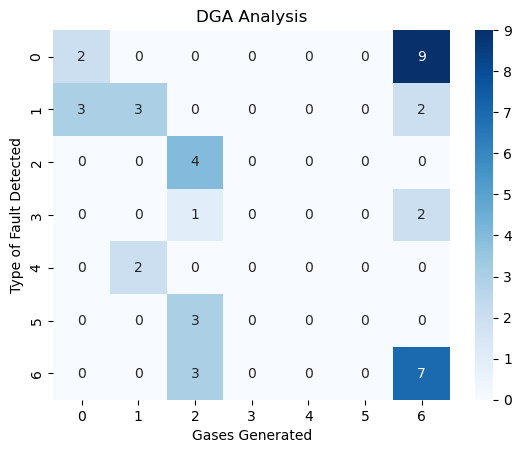

In [96]:
sns.heatmap(cm, annot = True, fmt="d", cmap = "Blues")
plt.xlabel("Gases Generated")
plt.ylabel("Type of Fault Detected")
plt.title("DGA Analysis")
plt.show()

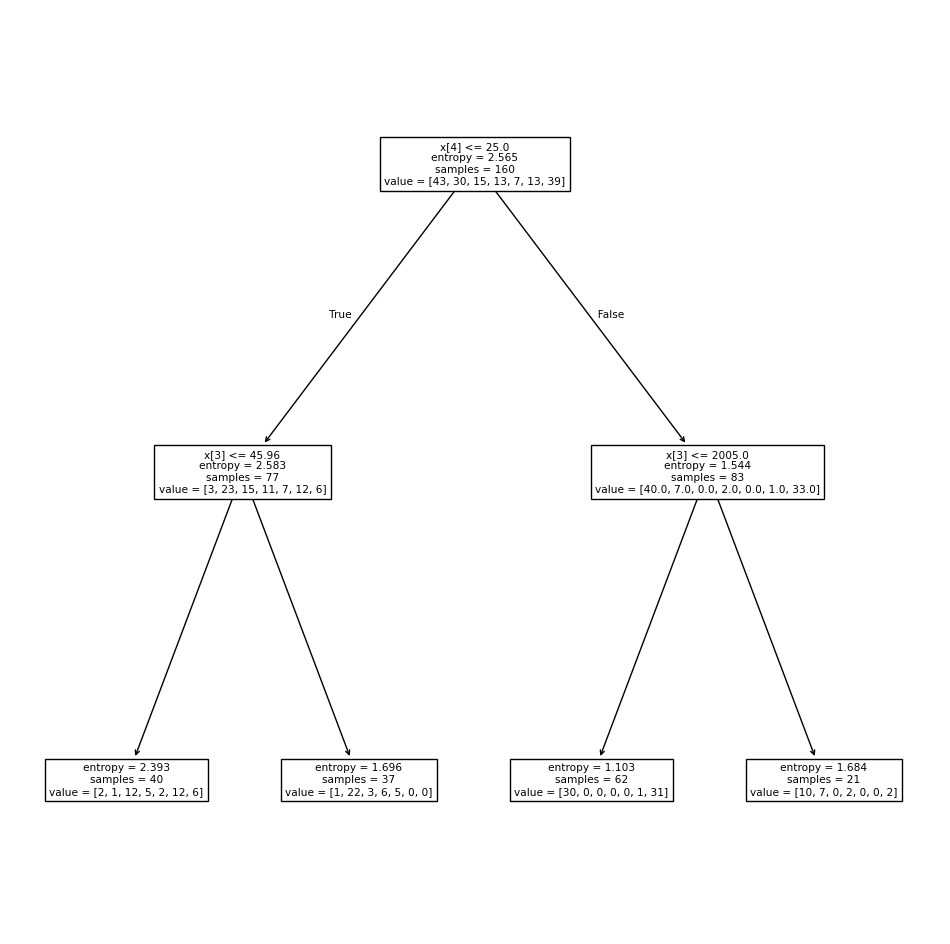

In [97]:
plt.figure(figsize = (12,12))
tree.plot_tree(df_en)
plt.show()

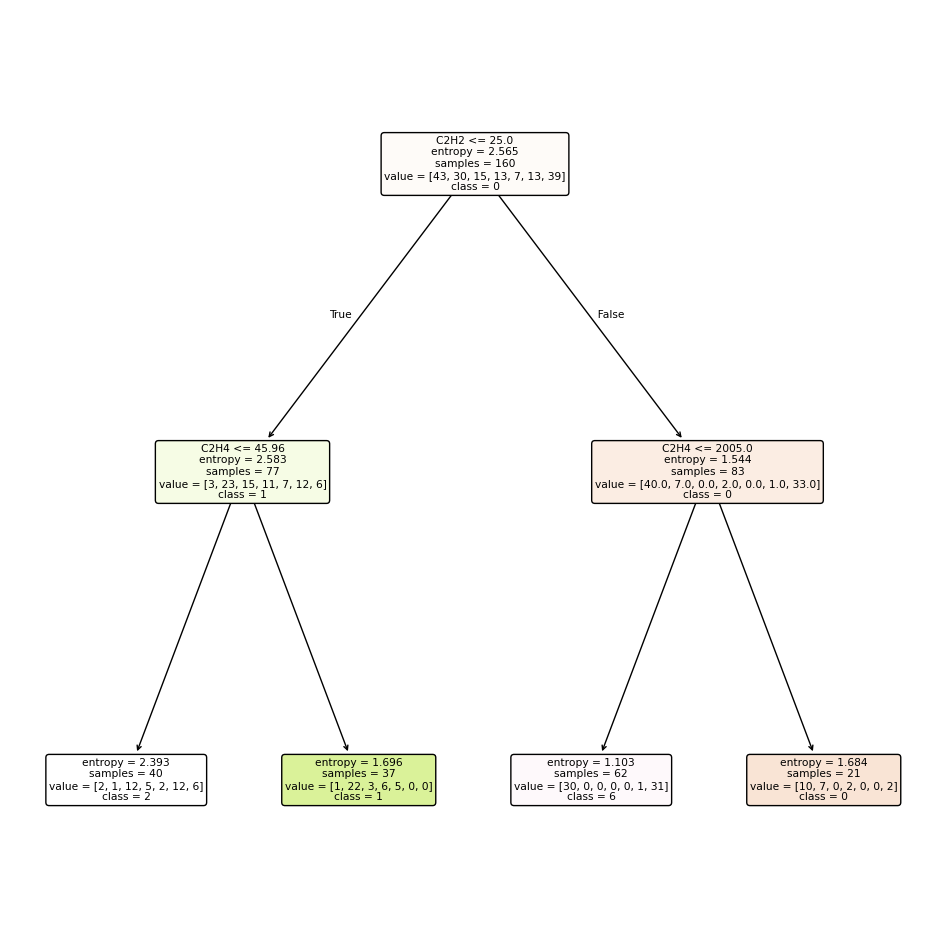

In [98]:
plt.figure(figsize = (12,12))
plot_tree(df_en, feature_names = x.columns, class_names = [str(c) for c in df_gini.classes_], filled = True, rounded = True)
plt.show()

In [99]:
print(classification_report(y_test, y_pred_en))

              precision    recall  f1-score   support

           0       0.40      0.18      0.25        11
           1       0.60      0.38      0.46         8
           2       0.36      1.00      0.53         4
           3       0.00      0.00      0.00         3
           4       0.00      0.00      0.00         2
           5       0.00      0.00      0.00         3
           6       0.35      0.70      0.47        10

    accuracy                           0.39        41
   macro avg       0.24      0.32      0.24        41
weighted avg       0.35      0.39      0.32        41



C:\Users\gupta\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\gupta\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\gupta\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [100]:
y_train_pred_gini = df_gini.predict(x_train)

In [101]:
train_accuracy = accuracy_score(y_train, y_train_pred_gini)
print("train_accuracy:", train_accuracy)
print("test_accuracy:", accuracy)

train_accuracy: 0.53125
test_accuracy: 0.3902439024390244


In [102]:
from sklearn.ensemble import RandomForestClassifier

In [103]:
rf = RandomForestClassifier(n_estimators = 50, max_features = "sqrt", max_depth = None, random_state = 42, oob_score = True)
rf.fit(x_train, y_train)

,n_estimators,50
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


In [104]:
y_pred_rf = rf.predict(x_test)

In [105]:
y_pred_proba_rf = rf.predict_proba(x_test)[:,1]

In [106]:
test_accuracy_rf = accuracy_score(y_test, y_pred_rf)
test_accuracy_rf

0.7073170731707317

In [107]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_rf

array([[9, 0, 0, 0, 0, 0, 2],
       [2, 5, 0, 0, 1, 0, 0],
       [0, 0, 4, 0, 0, 0, 0],
       [1, 1, 1, 0, 0, 0, 0],
       [0, 1, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 3, 0],
       [3, 0, 0, 0, 0, 0, 7]])

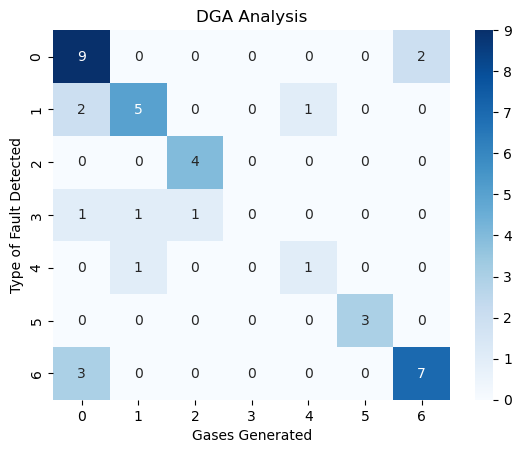

In [108]:
sns.heatmap(cm_rf, annot = True, fmt= "d", cmap = "Blues")
plt.xlabel("Gases Generated")
plt.ylabel("Type of Fault Detected")
plt.title("DGA Analysis")
plt.show()

In [109]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.60      0.82      0.69        11
           1       0.71      0.62      0.67         8
           2       0.80      1.00      0.89         4
           3       0.00      0.00      0.00         3
           4       0.50      0.50      0.50         2
           5       1.00      1.00      1.00         3
           6       0.78      0.70      0.74        10

    accuracy                           0.71        41
   macro avg       0.63      0.66      0.64        41
weighted avg       0.67      0.71      0.68        41



C:\Users\gupta\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\gupta\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\gupta\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [110]:
y_pred_train_rf = rf.predict(x_train)

In [111]:
train_accuracy_rf = accuracy_score(y_train, y_pred_train_rf)
train_accuracy_rf

1.0

In [112]:
rf_balanced = RandomForestClassifier(n_estimators = 50, class_weight = "balanced", random_state = 42)
rf_balanced.fit(x_train, y_train)

,n_estimators,50
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [113]:
y_pred_balanced = rf_balanced.predict(x_test)

In [114]:
test_accuracy_bal = accuracy_score(y_test, y_pred_balanced)
test_accuracy_bal

0.6585365853658537

In [115]:
print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.62      0.73      0.67        11
           1       0.67      0.75      0.71         8
           2       0.80      1.00      0.89         4
           3       0.00      0.00      0.00         3
           4       0.50      0.50      0.50         2
           5       1.00      0.67      0.80         3
           6       0.67      0.60      0.63        10

    accuracy                           0.66        41
   macro avg       0.61      0.61      0.60        41
weighted avg       0.63      0.66      0.64        41



In [116]:
from sklearn.metrics import precision_recall_curve

In [117]:
pip install imbalanced_learn

Note: you may need to restart the kernel to use updated packages.


In [118]:
from imblearn.over_sampling import SMOTE

In [119]:
sm = SMOTE(random_state = 42)
x_train_sm, y_train_sm = sm.fit_resample(x_train, y_train)

In [120]:
print(pd.Series(y_train_sm).value_counts())

Type
5    43
6    43
4    43
2    43
0    43
1    43
3    43
Name: count, dtype: int64


In [121]:
model_smote = RandomForestClassifier(random_state = 42)
model_smote.fit(x_train_sm, y_train_sm)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [122]:
y_pred_smote = model_smote.predict(x_test)

In [123]:
print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.59      0.91      0.71        11
           1       1.00      0.75      0.86         8
           2       0.75      0.75      0.75         4
           3       0.50      0.33      0.40         3
           4       0.33      0.50      0.40         2
           5       1.00      1.00      1.00         3
           6       0.83      0.50      0.62        10

    accuracy                           0.71        41
   macro avg       0.71      0.68      0.68        41
weighted avg       0.76      0.71      0.71        41



In [124]:
print(accuracy_score(y_test, y_pred_smote))

0.7073170731707317
